In [1]:
%pip install table-transformer

Note: you may need to restart the kernel to use updated packages.


In [ ]:
import matplotlib.patches as patches
import matplotlib.pyplot as plt
import warnings
from PIL import Image
from time import time

from table_transformer import TableExtractionPipeline

# https://huggingface.co/bsmock/tatr-pubtables1m-v1.0/resolve/main/pubtables1m_detection_detr_r18.pth
# https://huggingface.co/bsmock/TATR-v1.1-Pub/resolve/main/TATR-v1.1-Pub-msft.pth

with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    pipe = TableExtractionPipeline(
        det_device="cpu",
        str_device="cpu",
        det_model_path="./weights/pubtables1m_detection_detr_r18.pth",
        str_model_path="./weights/TATR-v1.1-Pub-msft.pth",
        easyocr_config={"lang_list": ["ru", "en"], "gpu": False},
    )

In [3]:
def show_image(image_path):
    image = Image.open(image_path)
    plt.imshow(image)
    plt.axis("off")
    plt.show()

def recognize_tables(image_path):
    start_time = time()
    table_objects, table_cells_coordinates, table_cells_text = pipe(image_path)
    end_time = time()
    elapsed_time = f"{end_time - start_time:.3f}"
    return table_objects, table_cells_coordinates, table_cells_text, elapsed_time

def show_bounding_boxes(image_path, table_objects, table_cells):
    image = Image.open(image_path)
    
    ax = plt.gca()
    ax.axis("off")
    ax.imshow(image)

    colors = ["red", "blue", "yellow", "green"]
    
    for objects, cells, color in zip(table_objects, table_cells, colors):
        table_bbox = None
        for object in objects:
            if object["label"] == "table":
                table_bbox = object["bbox"]
                break
        dx, dy = table_bbox[0], table_bbox[1]

        for row in cells:
            for cell in row["cells"]:
                x1, y1, x2, y2 = cell["cell"]
                x1, y1, x2, y2 = x1 + dx, y1 + dy, x2 + dx, y2 + dy
                bbox = [[x1, y1], [x2, y1], [x2, y2], [x1, y2]]
                
                rect = patches.Polygon(bbox, linewidth=1.5, edgecolor=color, facecolor="none")
                ax.add_patch(rect)
    
    plt.show()

def test_on_image(image_path):
    print(f"Изображение: {image_path}")
    show_image(image_path)

    print("Процесс распознавания:")
    objects, cells, tables, elapsed_time = recognize_tables(image_path)
    print()
    
    if not tables or tables[0].empty:
        print(f"Таблиц не обнаружено (время: {elapsed_time} секунд)")
        return

    print("Изображение с обнаруженными ячейками:")
    show_bounding_boxes(image_path, objects, cells)

    print(f"Распознанный текст (время: {elapsed_time} секунд):")
    for df in tables:
        display(df)

In [4]:
IMAGE_PATH_1 = "1.png"
IMAGE_PATH_2 = "2.png"
IMAGE_PATH_3 = "3.png"
IMAGE_PATH_4 = "4.png"
IMAGE_PATH_5 = "5.png"
IMAGE_PATH_6 = "6.png"
IMAGE_PATH_7 = "7.png"
IMAGE_PATH_8 = "8.png"
IMAGE_PATH_9 = "9.png"
IMAGE_PATH_10 = "10.png"

Изображение: 1.png


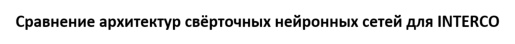

Процесс распознавания:

Таблиц не обнаружено (время: 0.222 секунд)


In [5]:
test_on_image(IMAGE_PATH_1)

Изображение: 2.png


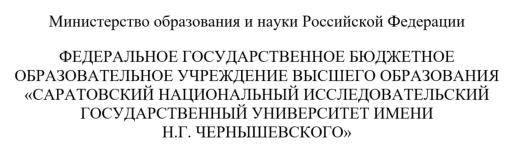

Процесс распознавания:


0it [00:00, ?it/s]

Max number of columns: 0

Таблиц не обнаружено (время: 0.504 секунд)


In [6]:
test_on_image(IMAGE_PATH_2)

Изображение: 3.png


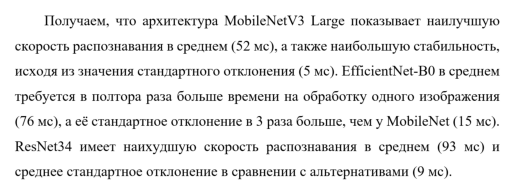

Процесс распознавания:


  0%|          | 0/1 [00:00<?, ?it/s]

Max number of columns: 8

Изображение с обнаруженными ячейками:


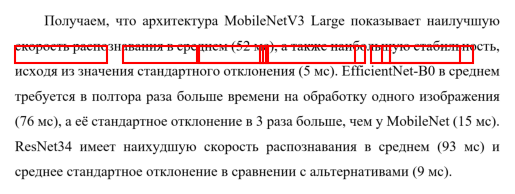

Распознанный текст (время: 2.635 секунд):


,0,1,2,3,4,5,6,7
0,ResNet34 имес,наихудшую,скорость,скорость,распознавания,распознавания,реднем (93,леднем (93 M


In [7]:
test_on_image(IMAGE_PATH_3)

Изображение: 4.png


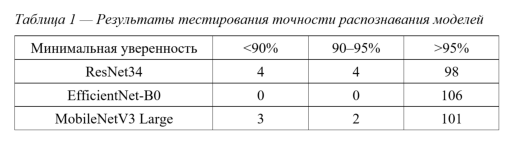

Процесс распознавания:


  0%|          | 0/4 [00:00<?, ?it/s]

Max number of columns: 4

Изображение с обнаруженными ячейками:


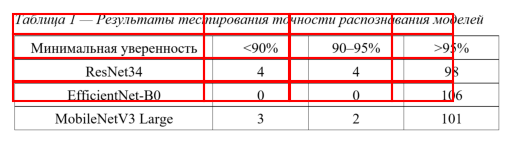

Распознанный текст (время: 3.964 секунд):


,0,1,2,3
0,Минимальная уверенность,<90%,9095%,>95%
1,ResNet34,98,,
2,EfficientNet-BO,106,,
3,MobileNetVЗ Large,3,101,


In [8]:
test_on_image(IMAGE_PATH_4)

Изображение: 5.png


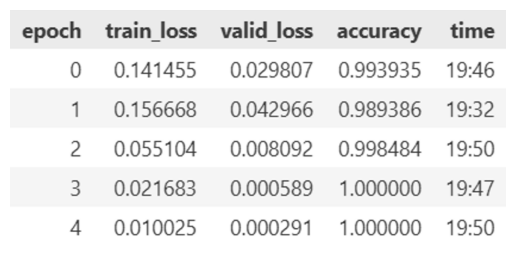

Процесс распознавания:


  0%|          | 0/6 [00:00<?, ?it/s]

Max number of columns: 5

Изображение с обнаруженными ячейками:


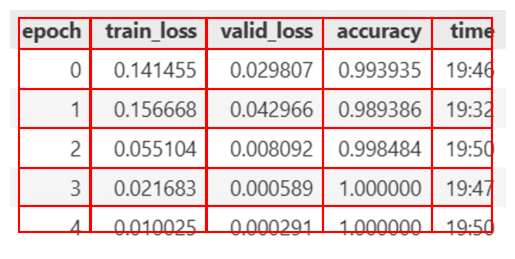

Распознанный текст (время: 5.453 секунд):


,0,1,2,3,4
0,epoch,train_loss,valid_loss,accuracy,time
1,0.141455,0.029807,0.993935,19.46,
2,0.156668,0.042966,0.989386,19.32,
3,2,0.055104,0.008092,0.998484,19.50
4,3,0.021683,0.000589,1.0ООО00,19.47
5,19.5n,,,,


In [9]:
test_on_image(IMAGE_PATH_5)

Изображение: 6.png


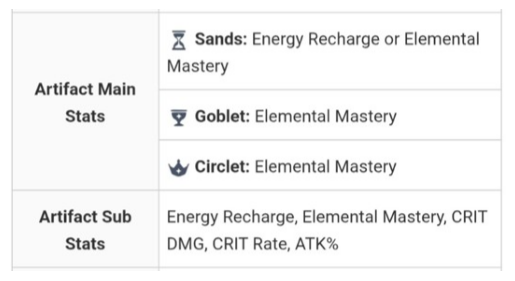

Процесс распознавания:


  0%|          | 0/5 [00:00<?, ?it/s]

Max number of columns: 2


  0%|          | 0/4 [00:00<?, ?it/s]

Max number of columns: 2

Изображение с обнаруженными ячейками:


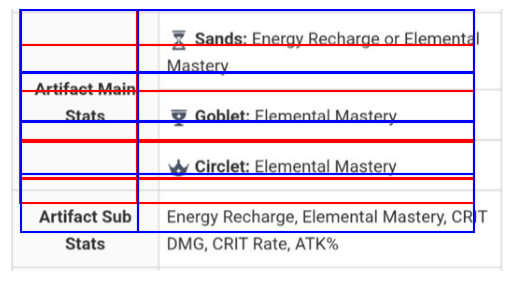

Распознанный текст (время: 5.285 секунд):


,0,1
0,Artifact Main,Mastery
1,Stats,Goblet: Elemental Mastery
2,Circlet: Elemental Mastery,
3,Artifact Sub,Energy Recharge; Elemental Mastery; CRIT
4,Stats,DMG; CRIT Rate; АТК%


,0,1
0,2 Sands: Energy Recharge or Elemental Mastery,
1,Stats,Goblet: Elemental Mastery
2,Circlet: Elemental Mastery,
3,Artifact Sub Stats,Energy Recharge; Elemental Mastery; CRIT DMG; ...


In [10]:
test_on_image(IMAGE_PATH_6)

Изображение: 7.png


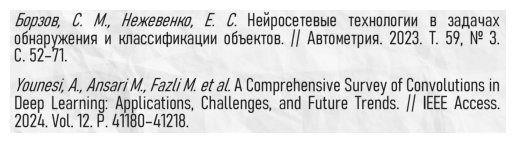

Процесс распознавания:


  0%|          | 0/1 [00:00<?, ?it/s]

Max number of columns: 9

Изображение с обнаруженными ячейками:


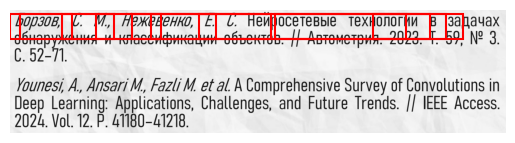

Распознанный текст (время: 3.395 секунд):


,0,1,2,3,4,5,6,7,8
0,"'unesi; А,","nesi; А , Ansari М , Fazli M: et al",Ansari,"iri M, Fazlr",Fazli M: et al A Comprehensive Survey of СОг,li M: et al A Comprc,al A Comprehensive Survey of Convol,hensive Survey of Convoluti,Of Convolutions


In [11]:
test_on_image(IMAGE_PATH_7)

Изображение: 8.png


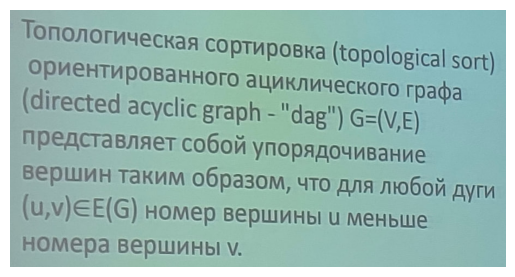

Процесс распознавания:


  0%|          | 0/2 [00:00<?, ?it/s]

Max number of columns: 2

Изображение с обнаруженными ячейками:


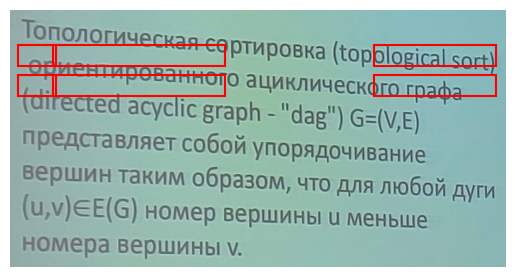

Распознанный текст (время: 1.532 секунд):


,0,1
0,(U !,"""ellG] номер"
1,HO^,мера вершины


In [12]:
test_on_image(IMAGE_PATH_8)

Изображение: 9.png


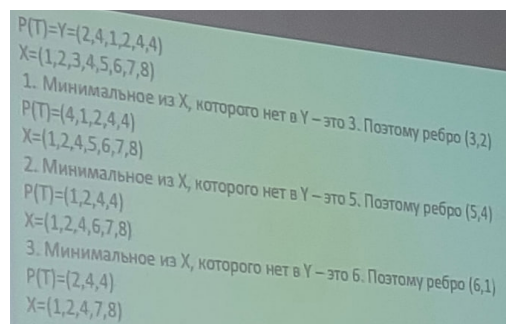

Процесс распознавания:


  0%|          | 0/6 [00:00<?, ?it/s]

Max number of columns: 1


  0%|          | 0/8 [00:00<?, ?it/s]

Max number of columns: 1

Изображение с обнаруженными ячейками:


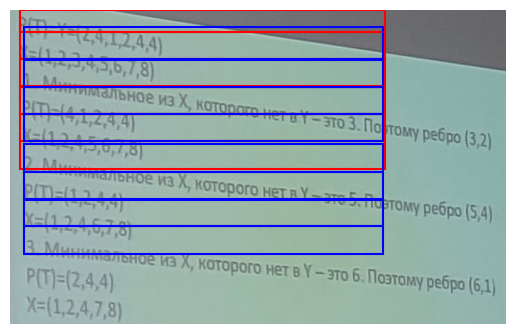

Распознанный текст (время: 6.057 секунд):


,0
0,(/12456 7
1,2 Миним
2,иа PID=l12 которОго НеТ в Y _ это
3,X=l12467
4,3 Минима
5,5U ^ которого нет в Y _ зто PITl-Q44) 6 По:


,0
0,"1,49,6,,8) 1 Мин"
1,Tanue Из > Hетл которог PITI4
2,5лU 9 ПО (1 2
3,го M
4,из 4 коtорОго P(T-(1244 вY Э10 5 Hет
5,X-(1 246791
6,3 Минималы
7,ноторого нет в Y _ это 6 П PITl-(244)


In [13]:
test_on_image(IMAGE_PATH_9)

Изображение: 10.png


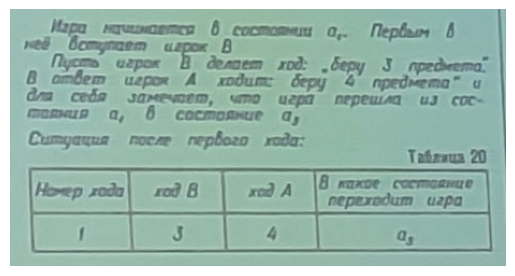

Процесс распознавания:

Таблиц не обнаружено (время: 0.356 секунд)


In [14]:
test_on_image(IMAGE_PATH_10)